<a href="https://colab.research.google.com/github/Giocrisrai/aprendizaje-refuerzo-duoc/blob/main/notebooks/09_lago_congelado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# 09 · Lago congelado
**Machine Learning — Duoc UC**

Este juego, el taxi y el péndulo son para mostrar en Colab. El algoritmo es el del notebook 01. El desafío del salmón sigue siendo el notebook 05.

El personaje está en un lago de 4 por 4. Parte en **S** y quiere llegar a **G**. **F** es hielo firme. **H** es un agujero: el episodio se acaba y no hay premio. Solo la meta paga **+1**.

```
S F F F
F H F H
F F F H
H F F G
```

Las acciones son izquierda, abajo, derecha y arriba. El ciclo es el de siempre: el entorno dice la casilla, el agente elige, el entorno devuelve la casilla nueva, la recompensa y si terminó.

Primero el hielo no resbala: la acción va donde se pidió. Es la grilla del héroe, con un agujero en vez de un zombi. Después el hielo resbala y a veces el paso sale de lado. Ahí el mundo tiene azar, como el precio ruidoso del centro de salmón.


In [1]:
#@title ⚙️ Configuración (en Colab instala Gymnasium y deja el juego listo)
import sys, subprocess

def _asegurar(paquete):
    try:
        return __import__(paquete)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])
        return __import__(paquete)

gymnasium = _asegurar("gymnasium")
numpy = _asegurar("numpy")
matplotlib = _asegurar("matplotlib")
print("Listo.", "gymnasium", gymnasium.__version__, "| numpy", numpy.__version__, "| matplotlib", matplotlib.__version__)


Listo. gymnasium 1.4.0 | numpy 2.5.4 | matplotlib 3.11.2


## El mapa y un paso

Hay 16 casillas, numeradas de izquierda a derecha y de arriba a abajo. La partida es la 0. La meta es la 15. Los agujeros son 5, 7, 11 y 12.

Un camino que llega, sin pisar agujeros: abajo, abajo, derecha, derecha, abajo, derecha.

La tabla Q parte en ceros y la recompensa de casi todos los pasos es 0. En el primer viaje solo cambia la celda que pisa la meta: el futuro todavía vale 0, así que no hay nada que copiar hacia atrás. En el segundo viaje esa celda ya vale algo y el paso anterior la hereda, descontada por γ. Es la misma historia del trofeo: primero 500 en la casilla de al lado, después 237 una casilla más atrás.


In [2]:
import numpy as np
import gymnasium as gym

NOMBRE = ("izquierda", "abajo", "derecha", "arriba")
CAMINO = (1, 1, 2, 2, 1, 2)  # abajo, abajo, derecha, derecha, abajo, derecha
alpha, gamma = 0.8, 0.95

def mostrar_mapa():
    lago = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)
    filas = lago.unwrapped.desc.astype(str)
    print("\n".join(" ".join(fila) for fila in filas))
    lago.close()

def dos_viajes():
    """Sigue el camino bueno dos veces y anota cada celda que cambia."""
    entorno = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)
    Q = np.zeros((entorno.observation_space.n, entorno.action_space.n))
    for viaje in (1, 2):
        estado, _ = entorno.reset(seed=0)
        print(f"\nviaje {viaje}")
        for accion in CAMINO:
            siguiente, recompensa, termino, _, _ = entorno.step(int(accion))
            futuro = 0.0 if termino else gamma * float(Q[siguiente].max())
            antes = float(Q[estado, accion])
            Q[estado, accion] = antes + alpha * (recompensa + futuro - antes)
            if Q[estado, accion] != antes:
                print(
                    f"  casilla {estado:2d}  {NOMBRE[accion]:10} → {siguiente:2d}"
                    f"   recompensa {recompensa:.0f}   futuro {futuro:.3f}"
                    f"   Q {antes:.3f} → {Q[estado, accion]:.3f}"
                )
            estado = siguiente
            if termino:
                break
    entorno.close()

mostrar_mapa()
dos_viajes()


S F F F
F H F H
F F F H
H F F G

viaje 1
  casilla 14  derecha    → 15   recompensa 1   futuro 0.000   Q 0.000 → 0.800

viaje 2
  casilla 10  abajo      → 14   recompensa 0   futuro 0.760   Q 0.000 → 0.608
  casilla 14  derecha    → 15   recompensa 1   futuro 0.000   Q 0.800 → 0.960


## Cómo se lee

En el viaje 1 la única línea es la meta: recompensa 1, futuro 0, y α = 0,8 se queda con **0,800**. Las casillas de antes no se mueven, porque su objetivo es 0 + 0.

En el viaje 2 el paso que cae justo antes de la meta ya ve ese 0,800. γ se queda con el 95%: futuro 0,760. Otra vez α se queda con una fracción: la celda pasa de 0 a **0,608**. En esa misma visita la meta sube de 0,800 a **0,960**. El premio empezó a caminar hacia atrás. Hacen falta más viajes para que llegue hasta la partida. Por eso el entrenamiento no es un episodio.


## Entrenar

Cada episodio baja ε: al principio la tabla está en cero y todo es exploración. Al final ε queda en 0,05. La política que se juega después es greedy, con ε = 0. En la grilla del notebook 01 ε se dejaba en 0,2 a propósito, para que la curva siguiera mostrando al zombi. Aquí lo bajamos para que el juego se vea resuelto.

La fórmula no cambia:

```
Q ← Q + α · (recompensa + γ · max Q(siguiente) − Q)
```

Si el episodio terminó, el futuro vale 0.


In [3]:
def entrenar(resbala, episodios, alpha=0.8, gamma=0.95, semilla=0):
    entorno = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=resbala)
    rng = np.random.default_rng(semilla)
    n_estados, n_acciones = entorno.observation_space.n, entorno.action_space.n
    Q = np.zeros((n_estados, n_acciones))
    retornos = np.empty(episodios)
    for episodio in range(episodios):
        epsilon = max(0.05, 1.0 * (1 - episodio / (0.8 * episodios)))
        estado, _ = entorno.reset(seed=semilla + episodio)
        total = 0.0
        for _ in range(100):
            if rng.random() < epsilon:
                accion = int(rng.integers(n_acciones))
            else:
                accion = int(np.argmax(Q[estado]))
            siguiente, recompensa, termino, truncado, _ = entorno.step(accion)
            futuro = 0.0 if termino else gamma * float(Q[siguiente].max())
            Q[estado, accion] += alpha * (recompensa + futuro - Q[estado, accion])
            total += recompensa
            estado = siguiente
            if termino or truncado:
                break
        retornos[episodio] = total
    entorno.close()
    return Q, retornos

def jugar(Q, resbala, episodios=50, semilla=10_000):
    entorno = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=resbala)
    totales = []
    for k in range(episodios):
        estado, _ = entorno.reset(seed=semilla + k)
        total = 0.0
        for _ in range(100):
            accion = int(np.argmax(Q[estado]))
            estado, recompensa, termino, truncado, _ = entorno.step(accion)
            total += recompensa
            if termino or truncado:
                break
        totales.append(total)
    entorno.close()
    return np.asarray(totales)

def flechas(Q):
    """La flecha es la acción greedy. El punto es hielo que no llegó a valer nada."""
    lago = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)
    desc = lago.unwrapped.desc
    lago.close()
    simbolo = ("←", "↓", "→", "↑")
    lineas = []
    for fila in range(4):
        celdas = []
        for col in range(4):
            indice = fila * 4 + col
            letra = desc[fila, col]
            if letra == b"H":
                celdas.append("H")
            elif letra == b"G":
                celdas.append("G")
            elif float(Q[indice].max()) == 0.0:
                celdas.append("·")
            else:
                celdas.append(simbolo[int(np.argmax(Q[indice]))])
        lineas.append(" ".join(celdas))
    return "\n".join(lineas)

Q_quieto, retornos_quieto = entrenar(resbala=False, episodios=400)
greedy_quieto = jugar(Q_quieto, resbala=False)
print("lago quieto, greedy llega a la meta:", float(greedy_quieto.mean()))
print("la flecha es la acción greedy; el punto es hielo sin valor")
print(flechas(Q_quieto))


lago quieto, greedy llega a la meta: 1.0
la flecha es la acción greedy; el punto es hielo sin valor
↓ ← · ·
↓ H ↓ H
→ ↓ ← H
H → → G


Matplotlib is building the font cache; this may take a moment.


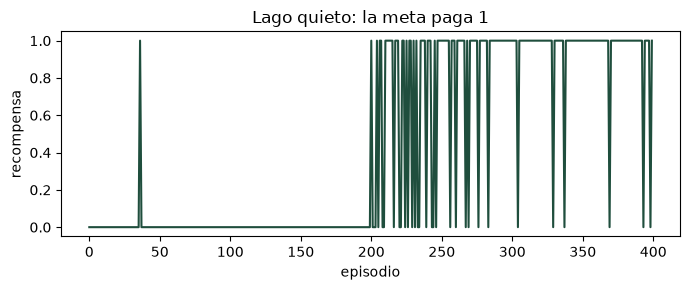

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3))
plt.plot(retornos_quieto, color="#1f4e3d")
plt.xlabel("episodio")
plt.ylabel("recompensa")
plt.title("Lago quieto: la meta paga 1")
plt.tight_layout()
plt.show()


## El hielo que resbala

En el mapa de arriba la partida apunta hacia abajo y, siguiendo las flechas, se llega a G sin pisar un agujero. Una flecha en una casilla que no está en ese camino puede apuntar a cualquier lado: esa casilla casi no se visitó. El punto es hielo que quedó en cero.

`is_slippery=True` es el lago de Gymnasium tal como viene en el libro de ejemplos: pedir «derecha» a veces termina en otra casilla. La fórmula es la misma. α baja a 0,1 y γ sube a 0,99: con hielo que resbala, un paso grande persigue un premio que a veces no llegó. Lo que cambia el resultado es el mundo.

La política greedy ya no gana todos los intentos. Un agujero se puede pisar sin haberlo elegido. En el centro de salmón pasa lo mismo con el sensor de oxígeno y la señal de precio: la observación miente un poco, y por eso el notebook 03 pide memoria y varias semillas antes de creer un solo número.


lago resbaloso, fracción de llegadas greedy: 0.74
recompensa media de los últimos 100 episodios de entrenamiento: 0.38


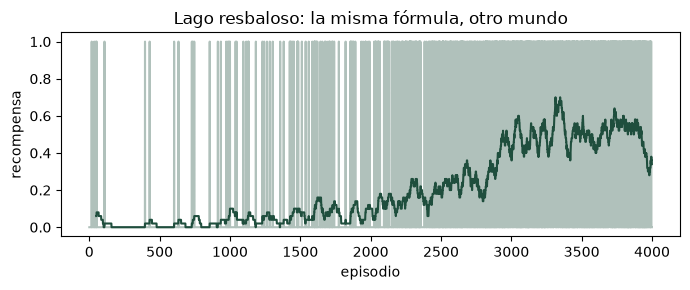

In [5]:
Q_resbala, retornos_resbala = entrenar(resbala=True, episodios=4000, alpha=0.1, gamma=0.99)
greedy_resbala = jugar(Q_resbala, resbala=True)
print("lago resbaloso, fracción de llegadas greedy:", round(float(greedy_resbala.mean()), 2))
print("recompensa media de los últimos 100 episodios de entrenamiento:", round(float(retornos_resbala[-100:].mean()), 2))

plt.figure(figsize=(7, 3))
plt.plot(retornos_resbala, color="#1f4e3d", alpha=0.35)
ventana = np.convolve(retornos_resbala, np.ones(50) / 50, mode="valid")
plt.plot(range(49, 49 + len(ventana)), ventana, color="#1f4e3d")
plt.xlabel("episodio")
plt.ylabel("recompensa")
plt.title("Lago resbaloso: la misma fórmula, otro mundo")
plt.tight_layout()
plt.show()


## Qué se lleva de este juego

La tabla cabe en 16 filas y se puede dibujar. En el taxi del notebook 10 hay 500 estados y la fórmula no se toca. En el péndulo del notebook 11 el estado es un número con decimales y la tabla obliga a cortarlo en cajas.

El desafío del notebook 05 no se resuelve copiando este lago. El ciclo sí es el mismo.
